In [33]:
import csv

In [34]:
X = []
with open('100.csv', 'r') as file:
    reader = csv.reader(file)
    for row in reader:
        data = []
        for i in range(len(row)):
            data.append(float(row[i]))
        X.append(data)
print(len(X))
print(len(X[0]))


100
10


In [35]:
def euclidean_distance(v1, v2):
    squared_sum = 0
    for i in range(len(v1)):
        difference = v1[i] - v2[i]
        squared_sum += difference * difference
    distance = squared_sum ** 0.5
    return distance

In [36]:
import random

def initialize_medoids(X, k):
    random.seed(42)
    medoids = random.sample(X, k)
    return [point[:] for point in medoids]

In [37]:
def assign_clusters(X, medoids):
    clusters = []
    for point in X:
        distances = []
        for medoid in medoids:
            distance = euclidean_distance(medoid, point)
            distances.append(distance)
        nearest_cluster = distances.index(min(distances))
        clusters.append(nearest_cluster)
    return clusters

In [38]:
def update_medoids(X, clusters, medoids, k):
    new_medoids = []

    for cluster_id in range(k):
        points = []
        for i in range(len(X)):
            if clusters[i] == cluster_id:
                points.append(X[i])
        if len(points) == 0:
            new_medoids.append(medoids[cluster_id])
            continue
        best_medoid = points[0]
        minimum_distance_sum = float('inf')
        for candidate in points:
            total_distance = 0
            for point in points:
                total_distance += euclidean_distance(candidate, point)
            if total_distance < minimum_distance_sum:
                minimum_distance_sum = total_distance
                best_medoid = candidate
        new_medoids.append(best_medoid[:])

    return new_medoids

In [39]:
def kmedoids(X, k, max_iterations=100):
    medoids = initialize_medoids(X, k)
    for iteration in range(max_iterations):
        clusters = assign_clusters(X, medoids)
        new_medoids = update_medoids( X, clusters, medoids, k)
        print("Iteration:", iteration + 1)
        if new_medoids == medoids:
            medoids = new_medoids
            break
        medoids = new_medoids
    clusters = assign_clusters(X, medoids)
    return clusters, medoids

In [40]:
clusters, medoids = kmedoids(X, k=3)

print("Cluster assignments:", clusters)
print("Medoids:", medoids)

Iteration: 1
Iteration: 2
Cluster assignments: [1, 1, 1, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 2, 1, 1, 1, 2, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 2, 1, 2, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
Medoids: [[8.775134522, 15.81108868, 91.23846566, 64.8416832, 41.70636003, 76.20712876, 16.54256223, 66.23015989, 63.92744687, 24.43880462], [68.43048887, 83.13098118, 77.60052621, 57.0164017, 67.15265144, 87.3549346, 36.00029828, 13.37866368, 14.7846134, 40.34027637], [67.24144695, 82.38871874, 85.97256941, 57.6145074, 61.6659761, 90.6094094, 31.83779072, 11.6535376, 12.72310046, 38.60228232]]


In [41]:
for i in range(5):
    print(X[i], "-> Cluster", clusters[i])

[68.43048887, 83.13098118, 77.60052621, 57.0164017, 67.15265144, 87.3549346, 36.00029828, 13.37866368, 14.7846134, 40.34027637] -> Cluster 1
[69.95780945, 83.86450417, 78.83343315, 57.22638492, 70.62717832, 92.77950684, 34.26004549, 8.910017343, 12.28679999, 37.51384706] -> Cluster 1
[68.63111679, 85.95103867, 81.82208819, 58.39686355, 69.67300528, 91.66966021, 33.20716571, 7.693424421, 17.3465145, 43.76014311] -> Cluster 1
[67.24144695, 82.38871874, 85.97256941, 57.6145074, 61.6659761, 90.6094094, 31.83779072, 11.6535376, 12.72310046, 38.60228232] -> Cluster 2
[65.5732762, 78.73762371, 78.7702658, 60.11804244, 66.10924194, 88.57695495, 38.19338768, 14.5199525, 14.77976988, 29.83441034] -> Cluster 1


In [42]:
def calculate_mean(point):
    total = 0

    for feature in point:
        total += feature

    mean = total / len(point)

    return mean


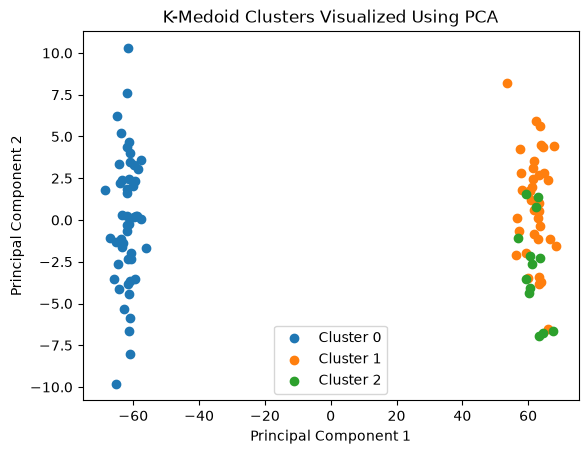

In [43]:

import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# Convert data into 2 dimensions for visualization
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

# Plot each cluster using its assigned cluster ID
for cluster_id in range(3):
    points = [
        X_2d[i]
        for i in range(len(X_2d))
        if clusters[i] == cluster_id
    ]

    if points:
        plt.scatter(
            [p[0] for p in points],
            [p[1] for p in points],
            label=f"Cluster {cluster_id}"
        )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Medoid Clusters Visualized Using PCA")
plt.legend()
plt.show()
